# Sales Performance Analysis & Business Insights

## Objective
Analyze sales data to identify trends, profitable categories, regional performance, and the impact of discounts on profit.

In [42]:
# Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
# Diplay settings

pd.set_option('display.max_columns', None)

print("Liberaries imported successfully!")

Liberaries imported successfully!


In [44]:
# Load Dataset

df = pd.read_csv("C:\\Users\\ACER\\OneDrive\\Desktop\\Sales_Performance_Analysis\\Dataset\\Sample - Superstore.csv", encoding="latin1")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [45]:
df.shape

(9994, 21)

In [46]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [47]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [49]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [50]:
# Checking Missing Values

df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [51]:
# Checking Duplicate Records

df.duplicated().sum()

np.int64(0)

In [52]:
# Checking Data Types

df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [53]:
# Convert Data Colmuns

df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

df.dtypes

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code               int64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

In [54]:
# Total Sales

total_sales = df['Sales'].sum()

total_sales

np.float64(2297200.8603)

In [55]:
# Total Profit

total_profit = df['Profit'].sum()

total_profit

np.float64(286397.0217)

In [56]:
# Total Orders

total_orders = df['Order ID'].nunique()

total_orders

5009

In [57]:
# Average Discount

avg_discount = df['Discount'].mean()

avg_discount

np.float64(0.1562027216329798)

In [58]:
# Business Summary

summary = pd.DataFrame({
    'Metric': [
        'Total Sales',
        'Total Profit',
        'Total Orders',
        'Average Discount'
    ],
    'Value': [
        total_sales,
        total_profit,
        total_orders,
        avg_discount
    ]
})

summary

,Metric,Value
0,Total Sales,2.297201e+06
1,Total Profit,2.863970e+05
2,Total Orders,5.009000e+03
3,Average Discount,1.562027e-01


In [59]:
# Creating Month Column

df['Month'] = df['Order Date'].dt.month
df['Year'] = df['Order Date'].dt.year

df[['Order Date','Month','Year']].head()

,Order Date,Month,Year
0,2016-11-08,11,2016
1,2016-11-08,11,2016
2,2016-06-12,6,2016
3,2015-10-11,10,2015
4,2015-10-11,10,2015


In [60]:
# Monthly Sales Analysis

monthly_sales = df.groupby(['Year','Month'])['Sales'].sum().reset_index()

monthly_sales.head()

,Year,Month,Sales
0,2014,1,14236.895
1,2014,2,4519.892
2,2014,3,55691.009
3,2014,4,28295.345
4,2014,5,23648.287


In [61]:
# Creating Month-Year Format

monthly_sales['Month-Year'] = (
    monthly_sales['Year'].astype(str)
    + '-'
    + monthly_sales['Month'].astype(str)
)

monthly_sales.head()

,Year,Month,Sales,Month-Year
0,2014,1,14236.895,2014-1
1,2014,2,4519.892,2014-2
2,2014,3,55691.009,2014-3
3,2014,4,28295.345,2014-4
4,2014,5,23648.287,2014-5


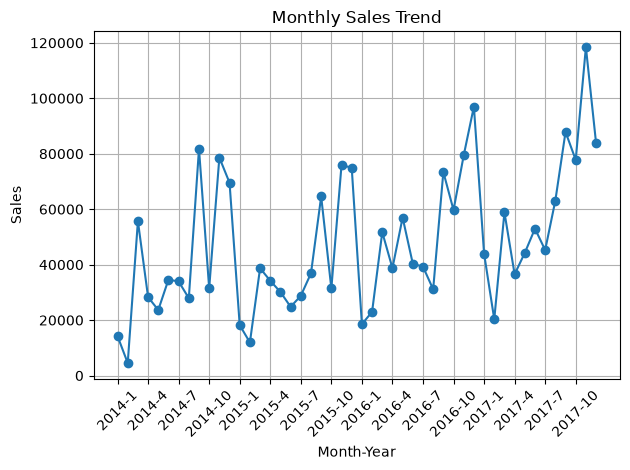

In [62]:
# Monthly Sales Trend

plt.Figure(figsize=(14,5))

plt.plot(
    monthly_sales['Month-Year'],
    monthly_sales['Sales'],
    marker = 'o'
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month-Year")
plt.ylabel("Sales")

plt.xticks(
    monthly_sales['Month-Year'][::3],
    rotation=45
)

plt.grid(True)

plt.tight_layout()

plt.savefig(
    r"C:\Users\ACER\OneDrive\Desktop\Sales_Performance_Analysis\Image\Monthly_Sales_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [63]:
# Monthly Profit Analysis

monthly_profit = df.groupby(['Year','Month'])['Profit'].sum().reset_index()

monthly_profit.head()

,Year,Month,Profit
0,2014,1,2450.1907
1,2014,2,862.3084
2,2014,3,498.7299
3,2014,4,3488.8352
4,2014,5,2738.7096


In [64]:
# Create Proper Month-Year Column

monthly_profit['Month-Year'] = pd.to_datetime(
    monthly_profit['Year'].astype(str)
    + '-'
    + monthly_profit['Month'].astype(str)
)

monthly_profit.head()

,Year,Month,Profit,Month-Year
0,2014,1,2450.1907,2014-01-01
1,2014,2,862.3084,2014-02-01
2,2014,3,498.7299,2014-03-01
3,2014,4,3488.8352,2014-04-01
4,2014,5,2738.7096,2014-05-01


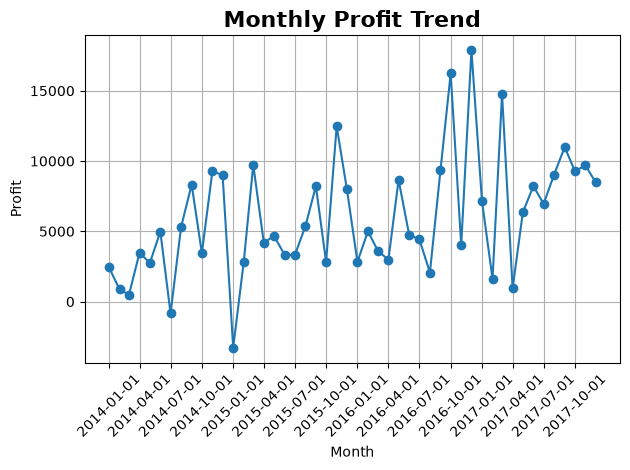

In [65]:
# Monthly Profit Trend Chart

plt.Figure(figsize=(14,5))

plt.plot(
    monthly_profit['Month-Year'],
    monthly_profit['Profit'],
    marker = 'o'
)

plt.title("Monthly Profit Trend", fontsize=16, fontweight='bold')

plt.xlabel("Month")
plt.ylabel("Profit")

plt.xticks(
    monthly_profit['Month-Year'][::3],
    rotation=45
)

plt.grid(True)

plt.tight_layout()

plt.savefig(
    r"C:\Users\ACER\OneDrive\Desktop\Sales_Performance_Analysis\Image\Monthly_Profit_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [66]:
# Sales by Category

category_sales = df.groupby('Category')['Sales'].sum().reset_index()

category_sales

,Category,Sales
0,Furniture,741999.7953
1,Office Supplies,719047.0320
2,Technology,836154.0330


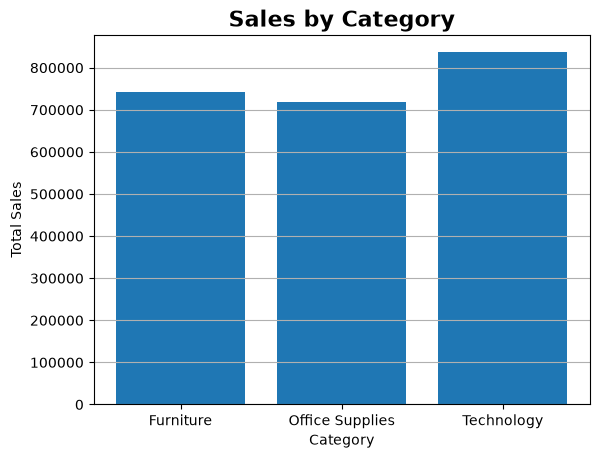

In [67]:
# Sales by Category Visualization

plt.Figure(figsize=(8,5))

plt.bar(
    category_sales['Category'],
    category_sales['Sales']
)

plt.title("Sales by Category", fontsize=16, fontweight='bold')

plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.grid(axis='y')

plt.savefig(
    r"C:\Users\ACER\OneDrive\Desktop\Sales_Performance_Analysis\Image\Sales_by_Category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [68]:
# Profit by Region

region_profit = df.groupby('Region')['Profit'].sum().reset_index()

region_profit

,Region,Profit
0,Central,39706.3625
1,East,91522.7800
2,South,46749.4303
3,West,108418.4489


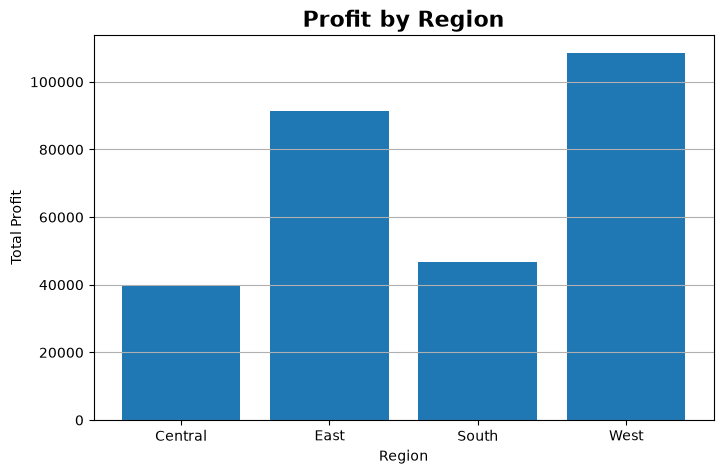

In [69]:
# Profit by Region Visulization

plt.figure(figsize=(8,5))

plt.bar(
    region_profit['Region'],
    region_profit['Profit']
)

plt.title("Profit by Region", fontsize=16, fontweight='bold')

plt.xlabel("Region")
plt.ylabel("Total Profit")

plt.grid(axis='y')

plt.savefig(
    r"C:\Users\ACER\OneDrive\Desktop\Sales_Performance_Analysis\Image\Profit_by_Region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [70]:
# Sales by Customer Segment

segment_sales = df.groupby('Segment')['Sales'].sum().reset_index()

segment_sales

,Segment,Sales
0,Consumer,1.161401e+06
1,Corporate,7.061464e+05
2,Home Office,4.296531e+05


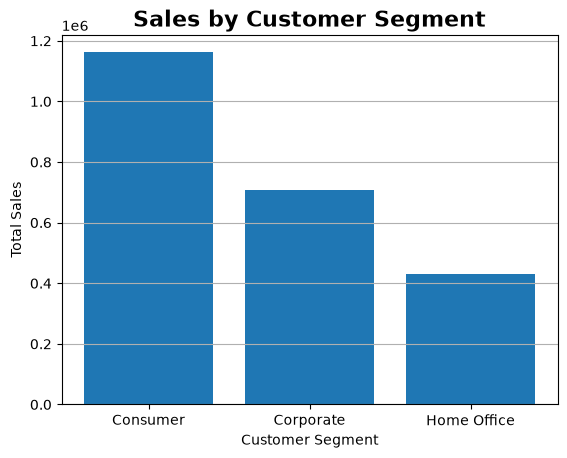

In [71]:
# Sales by Customer Segment Visualization

plt.Figure(figsize=(8,5))

plt.bar(
    segment_sales['Segment'],
    segment_sales['Sales']
)

plt.title("Sales by Customer Segment", fontsize=16, fontweight='bold')

plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")

plt.grid(axis='y')

plt.savefig(
    r"C:\Users\ACER\OneDrive\Desktop\Sales_Performance_Analysis\Image\Sales_by_Segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

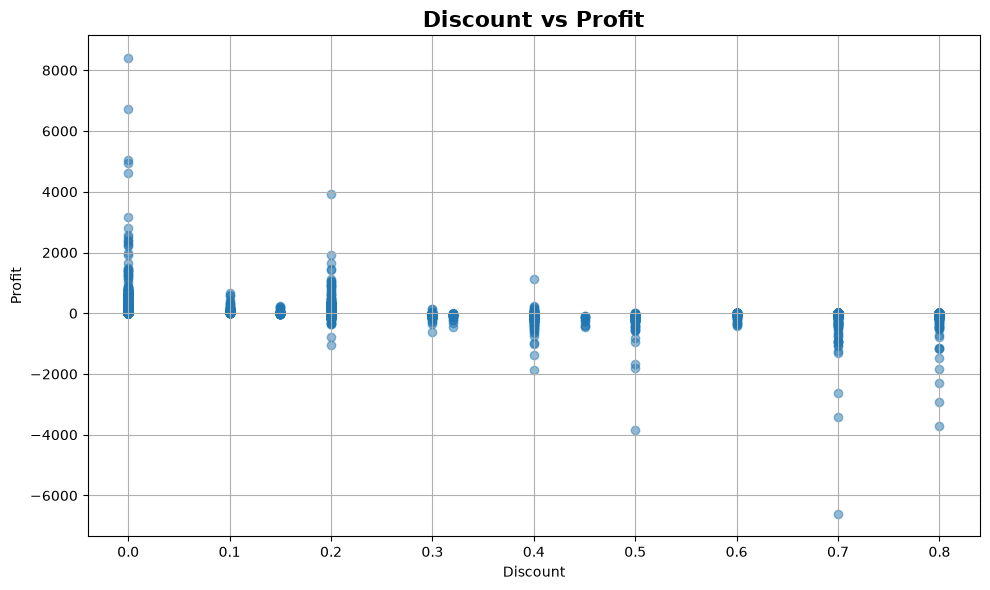

In [72]:
# Discount vs Profit Analysis

plt.figure(figsize=(10,6))

plt.scatter(
    df['Discount'],
    df['Profit'],
    alpha=0.5
)

plt.title("Discount vs Profit", fontsize=16, fontweight='bold')

plt.xlabel("Discount")
plt.ylabel("Profit")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    r"C:\Users\ACER\OneDrive\Desktop\Sales_Performance_Analysis\Image\Discount_vs_Profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [73]:
df[['Discount','Profit']].corr()

,Discount,Profit
Discount,1.000000,-0.219487
Profit,-0.219487,1.000000


## Business Insight

- Higher discounts generally reduce profitability.
- Products with large discounts often generate lower profit or even losses.
- The company should avoid unnecessary high discounts and instead use targeted promotional strategies.

In [74]:
# Top 10 Products by Sales

top_products = (
    df.groupby('Product Name')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

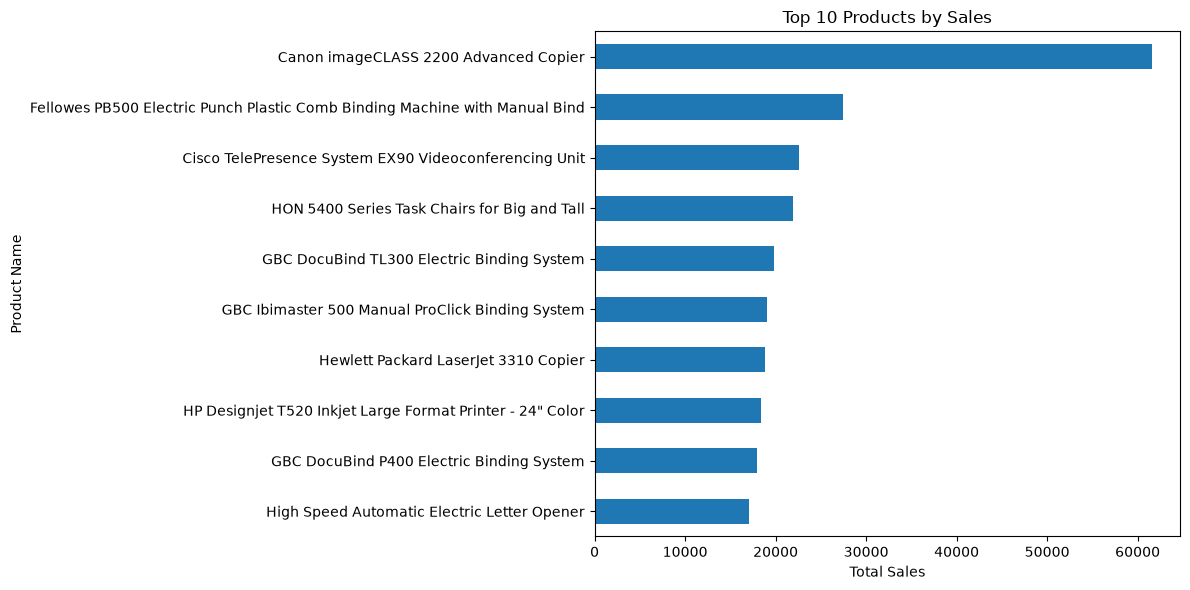

In [75]:
plt.figure(figsize=(12,6))

top_products.sort_values().plot(kind='barh')

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")

plt.tight_layout()

plt.savefig(
    r"C:\Users\ACER\OneDrive\Desktop\Sales_Performance_Analysis\Image\Top_10_Products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [76]:
# Top 10 Customers

top_customers = (
    df.groupby('Customer Name')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64

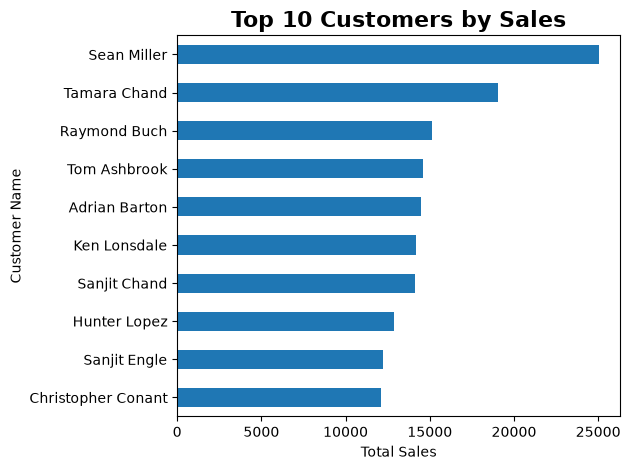

In [77]:
# Top 10 Customers by Sales

plt.Figure(figsize=(10,6))

top_customers.sort_values().plot(kind='barh')

plt.title("Top 10 Customers by Sales", fontsize=16, fontweight='bold')
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")

plt.tight_layout()

plt.savefig(
    r"C:\Users\ACER\OneDrive\Desktop\Sales_Performance_Analysis\Image\Top_10_Customers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

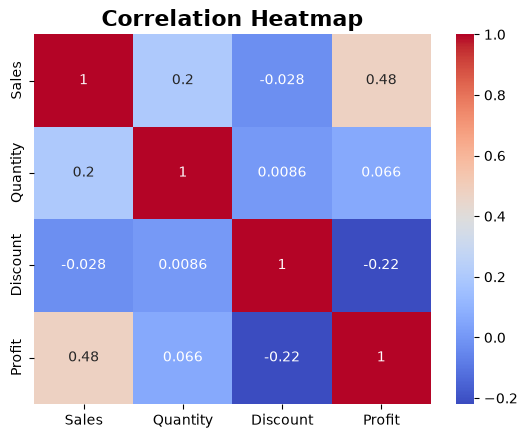

In [78]:
# Correlation Heatmap

plt.Figure(figsize=(8,5))

sns.heatmap(
    df[['Sales','Quantity','Discount','Profit']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap", fontsize=16, fontweight='bold')

plt.savefig(
    r"C:\Users\ACER\OneDrive\Desktop\Sales_Performance_Analysis\Image\Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [79]:
# Export Cleaned Dataset

df.to_csv(
    r"C:\Users\ACER\OneDrive\Desktop\Sales_Performance_Analysis\Dataset\Superstore_Cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


# Business Insights Report

## Key Findings

### 1. Sales Performance
The company generated total sales of approximately $2.29 million with 5,009 unique orders.

### 2. Profit Analysis
The business achieved a total profit of approximately $286K, showing overall positive performance.

### 3. Category Performance
Technology, Furniture, and Office Supplies categories contribute differently to revenue. The highest-performing category can be identified from category sales analysis.

### 4. Regional Performance
Regional analysis shows differences in profitability. The best-performing region should be prioritized for future growth strategies.

### 5. Customer Segment Analysis
The Consumer segment contributes the highest revenue compared to Corporate and Home Office segments.

### 6. Discount Impact
Higher discounts have a negative impact on profitability. The company should use discounts strategically to avoid reducing margins.

### 7. Sales Trend
Monthly analysis shows seasonal variations in sales, with certain months generating significantly higher revenue.